In [1]:
import pandas as pd
from uniguide.data.loading import load_raw

reviews, courses = load_raw()
names = reviews["reviewers"].str.replace(r"^By\s+", "", regex=True).str.strip()
print(names.value_counts().describe(percentiles=[0.5, 0.9, 0.99, 0.999]))
print(reviews["rating"].value_counts(normalize=True).sort_index())

count    283643.000000
mean          5.128669
std          13.419420
min           1.000000
50%           3.000000
90%           9.000000
99%          37.000000
99.9%       113.000000
max        5412.000000
Name: count, dtype: float64
rating
1    0.011930
2    0.011128
3    0.033205
4    0.155840
5    0.787898
Name: proportion, dtype: float64


In [2]:
from uniguide.config import get_path
from uniguide.data import stats

processed = get_path("processed")
inter = pd.read_parquet(processed / "interactions.parquet")
courses = pd.read_parquet(processed / "courses_base.parquet")
pd.read_csv(get_path("results") / "tables" / "filtering_log.csv")

,step,n_rows,n_users,n_courses
0,raw,1454711,287808,604
1,drop incomplete rows,1454558,287785,604
2,keep known courses,1454558,287785,604
3,drop generic users,1449143,283618,604
4,parse dates,1449143,283618,604
5,"drop duplicate (user, course)",505177,283618,604
6,drop suspected homonyms,504952,283616,604
7,"filter users>=5, courses>=50",138756,14792,422
8,sample 30000 users,138756,14792,422
9,re-filter after sampling,138756,14792,422


In [3]:
pd.Series(stats.basic_stats(inter))

n_users                         14792.000000
n_courses                         422.000000
n_interactions                 138756.000000
sparsity                            0.977771
avg_interactions_per_user           9.380476
avg_interactions_per_course       328.805687
top10pct_courses_share              0.443484
share_relevant                      0.927657
dtype: float64

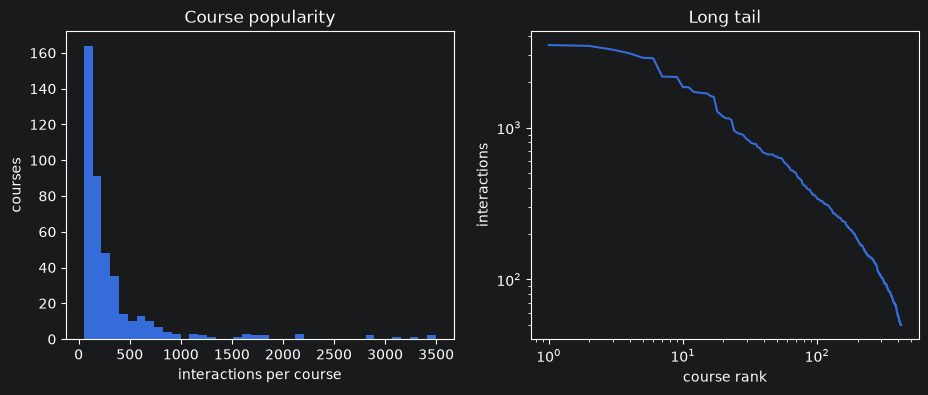

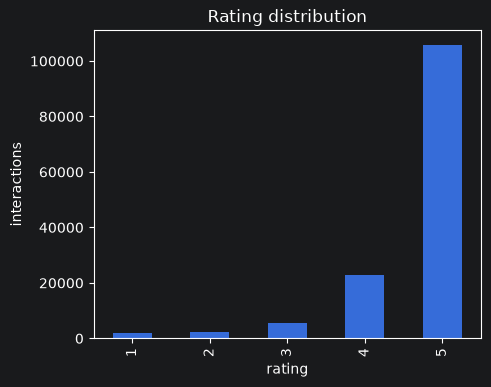

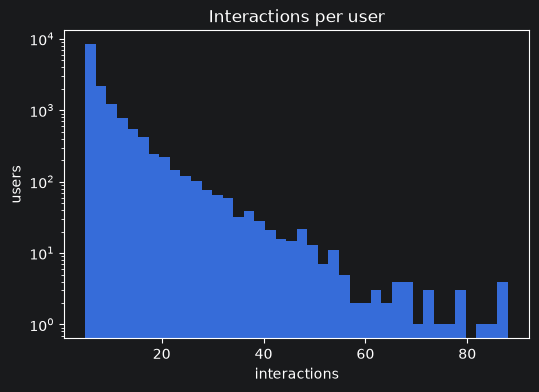

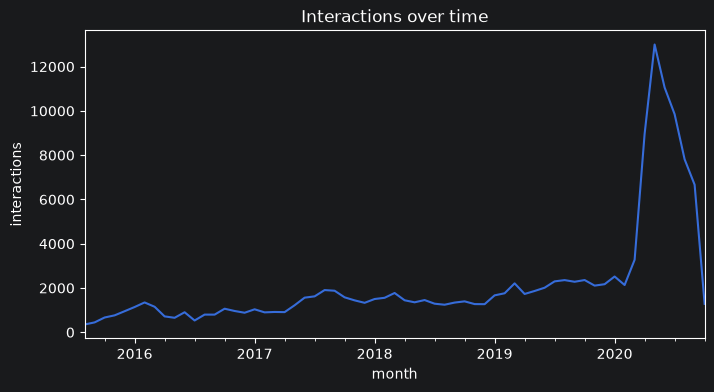

In [4]:
for name, fn in [("popularity", stats.plot_popularity),
                 ("ratings", stats.plot_rating_distribution),
                 ("reviews_per_user", stats.plot_reviews_per_user),
                 ("time", stats.plot_time)]:
    fig = fn(inter)
    stats.save_fig(fig, name)

In [5]:
top = inter.groupby("course_id").size().rename("n").nlargest(10).reset_index()
top.merge(courses[["course_id", "name", "institution"]], on="course_id")

,course_id,n,name,institution
0,python,3499,Programming for Everybody (Getting Started wit...,University of Michigan
1,neural-networks-deep-learning,3454,Neural Networks and Deep Learning,DeepLearning.AI
2,machine-learning,3262,Machine Learning,Stanford University
3,python-data,3086,Python Data Structures,University of Michigan
4,technical-support-fundamentals,2886,Technical Support Fundamentals,Google
5,learning-how-to-learn,2864,Learning How to Learn: Powerful mental tools t...,University of California San Diego
6,what-is-datascience,2169,What is Data Science?,IBM
7,python-network-data,2162,Using Python to Access Web Data,University of Michigan
8,deep-neural-network,2156,Improving Deep Neural Networks: Hyperparameter...,DeepLearning.AI
9,the-science-of-well-being,1848,The Science of Well-Being,Yale University
